In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pyglimpse
import numpy as np

# Import Datasets

In [26]:
# raw datasets
noise_311 = pd.read_csv('311_Service_Requests_from_2020_to_Present_20260302.csv')
cdta_population = pd.read_csv('cdta_population.csv')

In [27]:
# make copy of noise_311 for manipulation
noise_311_copy = noise_311.copy()

## Part 1 - Clean Data

In [28]:
# clean data

# Convert to datetime
noise_311_copy["Created Date"] = pd.to_datetime(noise_311_copy["Created Date"], errors="coerce")
noise_311_copy["Closed Date"] = pd.to_datetime(noise_311_copy["Closed Date"], errors="coerce")

# Extract hour for later (optional flex)
noise_311_copy["created_hour"] = noise_311_copy["Created Date"].dt.hour

# Drop unspecified
noise_311_copy = noise_311_copy[noise_311_copy["Community Board"] != "0 Unspecified"]

# Extract numeric code
noise_311_copy["cb_number"] = noise_311_copy["Community Board"].str.extract(r"(\d+)").astype(float)
noise_311_copy["cb_number"] = noise_311_copy["cb_number"].astype("Int64")

# Extract borough name
noise_311_copy["cb_boro"] = noise_311_copy["Community Board"].str.extract(r"\d+\s+(.*)")
noise_311_copy["cb_boro"] = noise_311_copy["cb_boro"].str.title()


/var/folders/sv/tjyf1wqj5hg7zz65thhq45780000gn/T/ipykernel_48997/2819343863.py:4: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

/var/folders/sv/tjyf1wqj5hg7zz65thhq45780000gn/T/ipykernel_48997/2819343863.py:5: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



### Standardize Key Fields for Question 1

In [29]:
noise_311_copy["Problem"] = noise_311_copy["Problem (formerly Complaint Type)"].str.strip()
noise_311_copy["Descriptor"] = noise_311_copy["Problem Detail (formerly Descriptor)"].str.strip()
noise_311_copy["Location Type"] = noise_311_copy["Location Type"].str.strip()

In [30]:
# drop rows with missing values in key columns
q1_df = noise_311_copy.dropna(subset=["Problem", "Descriptor", "Location Type"])

## PART 2 — Pareto Chart for Problem, Descriptor, Location Type

### Function to build Pareto Chart

In [31]:
def pareto_chart(data, column, top_n=10):
    
    counts = (
        data[column]
        .value_counts()
        .reset_index()
    )
    
    counts.columns = [column, "count"]
    counts["count"] = counts["count"].astype(int)
    
    counts["percent"] = counts["count"] / counts["count"].sum()
    counts["cum_percent"] = counts["percent"].cumsum()
    
    top = counts.head(top_n).copy()
    
    fig, ax1 = plt.subplots(figsize=(10,6))
    
    # --- BARPLOT ---
    sns.barplot(
        data=top,
        y=column,
        x="count",
        ax=ax1
    )
    
    # --- ADD COUNT LABELS TO BARS ---
    for i, v in enumerate(top["count"]):
        ax1.text(
            v,                 # x position (end of bar)
            i,                 # y position (bar index)
            f" {v:,}",         # formatted count with commas
            va='center'
        )
    
    # --- CUMULATIVE LINE ---
    ax2 = ax1.twiny()
    ax2.plot(
        top["cum_percent"],
        top[column],
        marker="o"
    )
    
    ax1.set_title(f"Top {top_n} {column} Categories and Cumulative Share")
    ax1.set_xlabel("Count")
    ax1.set_ylabel("")
    
    ax2.set_xlim(0,1)
    ax2.set_xlabel("Cumulative %")
    
    plt.tight_layout()
    plt.show()
    
    return counts

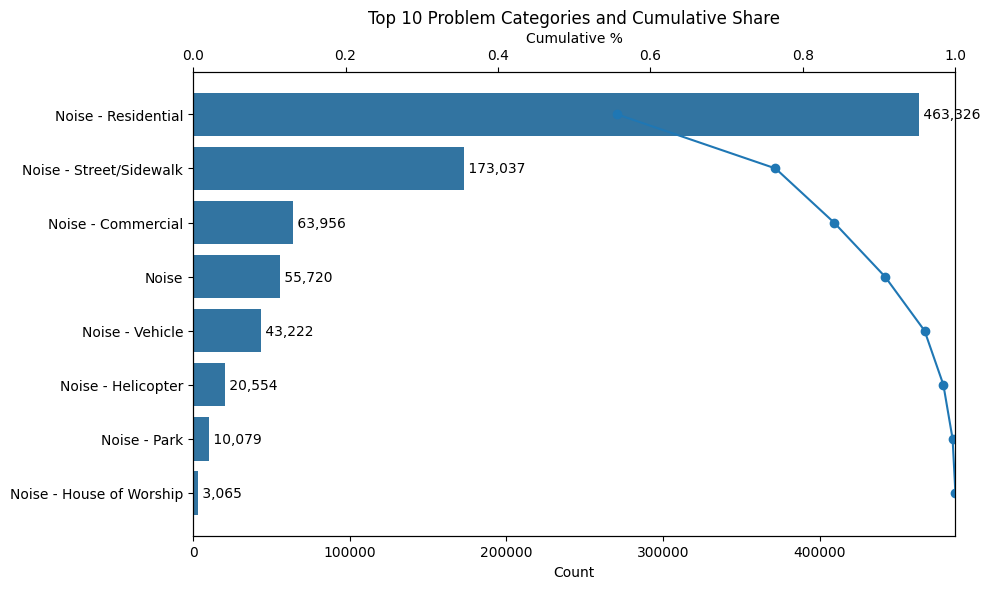

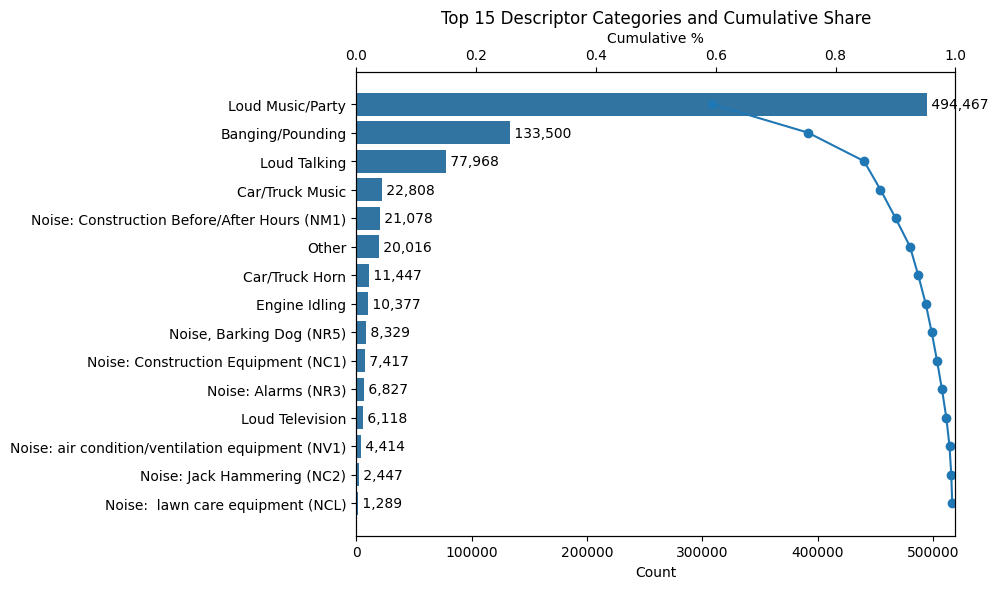

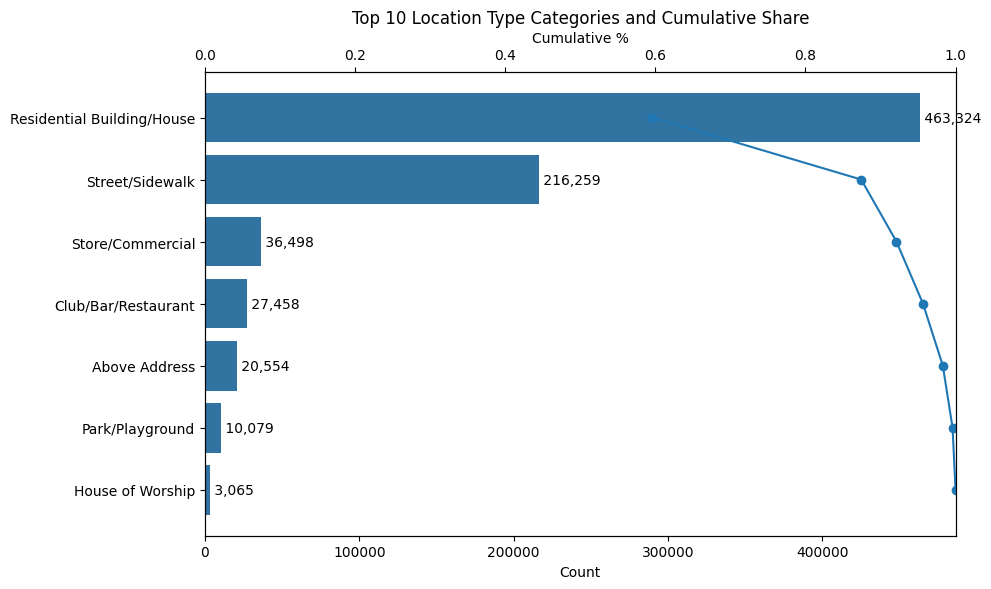

In [165]:
# Generate Pareto charts for the three key columns
problem_counts = pareto_chart(noise_311_copy, "Problem", top_n=10)
descriptor_counts = pareto_chart(noise_311_copy, "Descriptor", top_n=15)
location_counts = pareto_chart(noise_311_copy, "Location Type", top_n=10)

## PART 3 — Sunburst

In [166]:
# Prepare data for sunburst chart
sunburst_df = (
    noise_311_copy
    .groupby(["Problem", "Descriptor", "Location Type"])
    .size()
    .reset_index(name="count")
)

In [167]:
# Create sunburst chart

fig = px.sunburst(
    sunburst_df,
    path=["Problem", "Descriptor", "Location Type"],
    values="count",
    color="Problem",
)

fig.update_layout(
    title="Hierarchy of 2025 Noise Complaints",
    margin=dict(t=50, l=25, r=25, b=25)
)

fig.show()

## PART 4 — Descriptor × Location Heatmap

In [168]:
# Create pivot table for heatmap
# Prepare data for heatmap of top descriptors by location type
top_descriptors = descriptor_counts.head(15)["Descriptor"]

heat_df = (
    noise_311_copy[noise_311_copy["Descriptor"].isin(top_descriptors)]
    .groupby(["Descriptor", "Location Type"])
    .size()
    .unstack(fill_value=0)
)

# Normalize within descriptor
heat_df = heat_df.div(heat_df.sum(axis=1), axis=0)

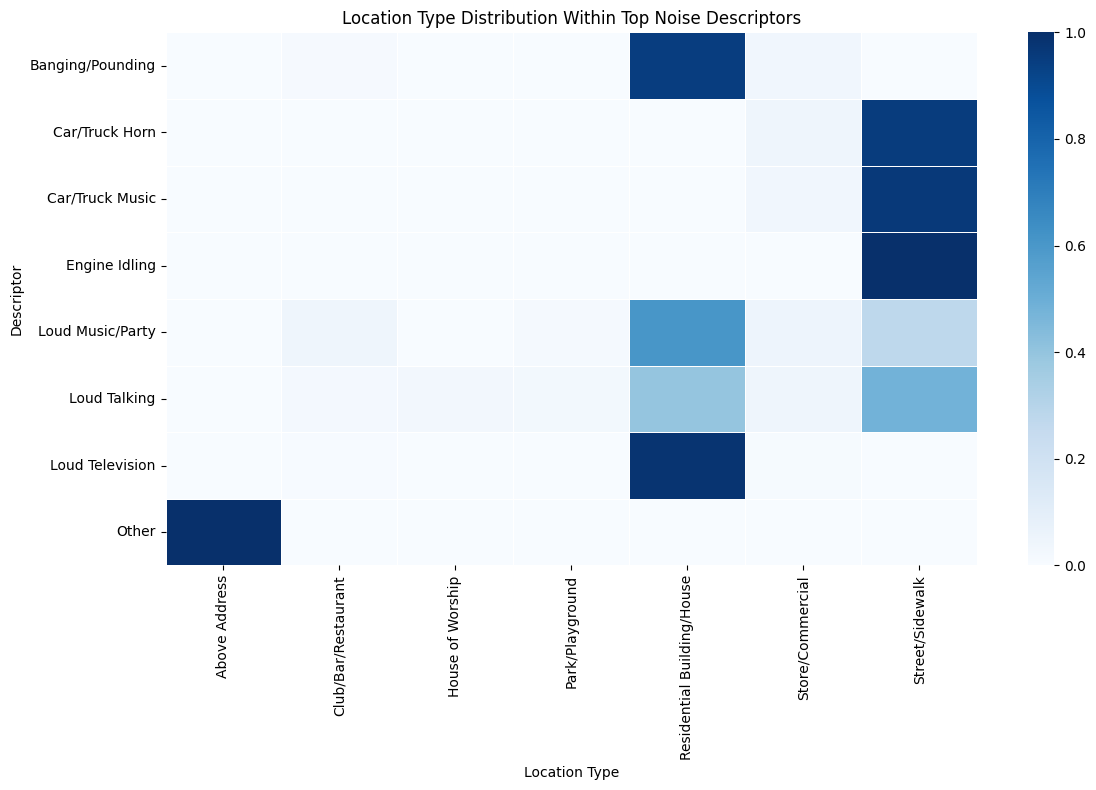

In [169]:
# Create heatmap
plt.figure(figsize=(12,8))

sns.heatmap(
    heat_df,
    cmap="Blues",
    linewidths=0.5
)

plt.title("Location Type Distribution Within Top Noise Descriptors")
plt.xlabel("Location Type")
plt.ylabel("Descriptor")
plt.tight_layout()
plt.show()

## PART 5 — Time-of-Day Insight

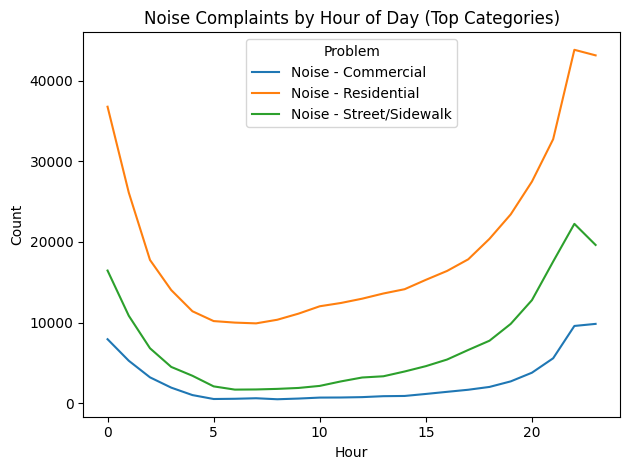

In [170]:
# Analyze temporal patterns for top problem categories
top_problems = problem_counts.head(3)["Problem"]

time_df = (
    noise_311_copy[noise_311_copy["Problem"].isin(top_problems)]
    .groupby(["created_hour", "Problem"])
    .size()
    .reset_index(name="count")
)

sns.lineplot(
    data=time_df,
    x="created_hour",
    y="count",
    hue="Problem"
)

plt.title("Noise Complaints by Hour of Day (Top Categories)")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## PART 6 — Time-of-year Insight

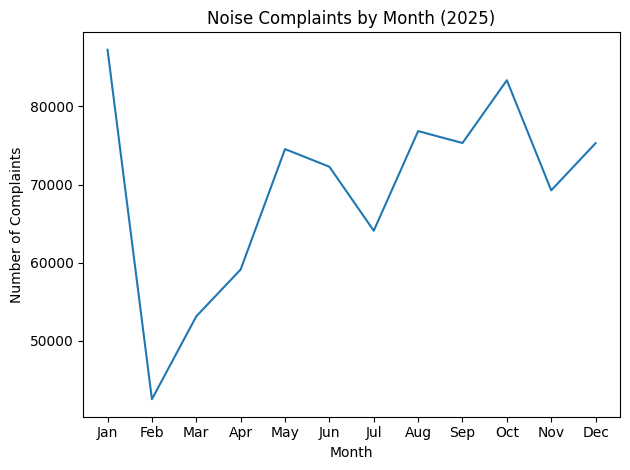

In [171]:
# --- Noise complaints by month ---

noise_311_copy["month"] = noise_311_copy["Created Date"].dt.month

month_counts = (
    noise_311_copy.groupby("month")
      .size()
      .reset_index(name="count")
)

import calendar
month_counts["month_name"] = month_counts["month"].apply(lambda x: calendar.month_abbr[x])

fig_month = px.line(
    month_counts,
    x="month_name",
    y="count",
    markers=True,
    title="Noise Complaints by Month (2025)",
    labels={"month_name": "Month", "count": "Number of Complaints"}
)

fig_month.update_layout(
    template="simple_white",
    title_font_size=20
)

fig_month.show()

sns.lineplot(
    data=month_counts,
    x="month_name",
    y="count"
)

plt.title("Noise Complaints by Month (2025)")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()


# Maps

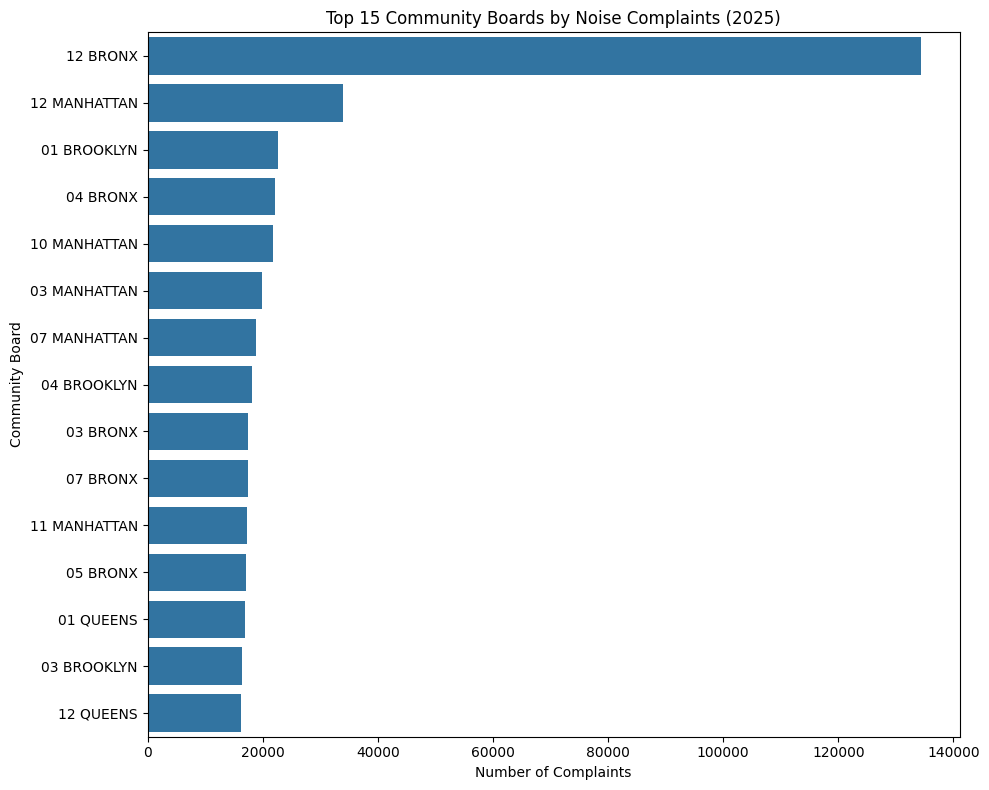

In [172]:
# Analyze spatial distribution by community board
cb_counts = (
    noise_311_copy.groupby("Community Board")
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.barplot(data=cb_counts.head(15), y="Community Board", x="count")
plt.title("Top 15 Community Boards by Noise Complaints (2025)")
plt.xlabel("Number of Complaints")
plt.ylabel("Community Board")
plt.tight_layout()

In [73]:
# Map borough names to codes for later use
boro_map = {
    "Bronx": "BX",
    "Brooklyn": "BK",
    "Manhattan": "MN",
    "Queens": "QN",
    "Staten Island": "SI"
}

In [173]:
# Create CDTA code by combining borough code and zero-padded community board number
noise_311_copy["cdta"] = (
    noise_311_copy["cb_boro"].map(boro_map) +
    noise_311_copy["cb_number"].astype(str).str.zfill(2)
)

In [174]:
# Calculate complaints per capita by CDTA
cb_counts = (
    noise_311_copy
    .groupby("cdta")
    .size()
    .reset_index(name="complaints")
)

# Merge with population data to calculate rates
cb_rate = cb_counts.merge(
    cdta_population[["cdta", "total_pop"]],
    on="cdta",
    how="left"
)

In [175]:
# Calculate complaints per 1000 residents
cb_rate["complaints_per_1000"] = (
    cb_rate["complaints"] /
    cb_rate["total_pop"] * 1000
)

In [176]:
# Sort by complaints per 1000 residents
cb_rate = cb_rate.sort_values(
    "complaints_per_1000",
    ascending=False
)

In [177]:
# Filter out CDTA areas with very small populations to avoid skewed rates
cb_rate_clean = cb_rate[cb_rate["total_pop"] >= 500]

In [178]:
# Sort again after filtering
top_cb = cb_rate_clean.sort_values(
    "complaints_per_1000",
    ascending=False
)

# Also look at bottom CDTA areas by rate
bottom_cb = cb_rate_clean.sort_values(
    "complaints_per_1000",
    ascending=True
)

In [179]:
print(top_cb.head(10))
print(bottom_cb.head(10))

    cdta  complaints  total_pop  complaints_per_1000
31  BX12      134385     163489           821.981907
46  MN12       33978     180206           188.550881
22  BX03       17409      93755           185.686097
44  MN10       21736     130440           166.636001
3   BK04       18186     120747           150.612438
23  BX04       22115     150436           147.006036
45  MN11       17201     125771           136.764437
43  MN09       14660     110458           132.720129
39  MN05        8437      63600           132.657233
24  BX05       17109     132584           129.042720
    cdta  complaints  total_pop  complaints_per_1000
69  SI03        4228     164723            25.667332
58  QN11        3423     122211            28.008935
11  BK12        6545     205377            31.868223
68  SI02        5010     140795            35.583650
42  MN08        8455     231983            36.446636
70  SI95          21        566            37.102473
9   BK10        5122     136071            37.

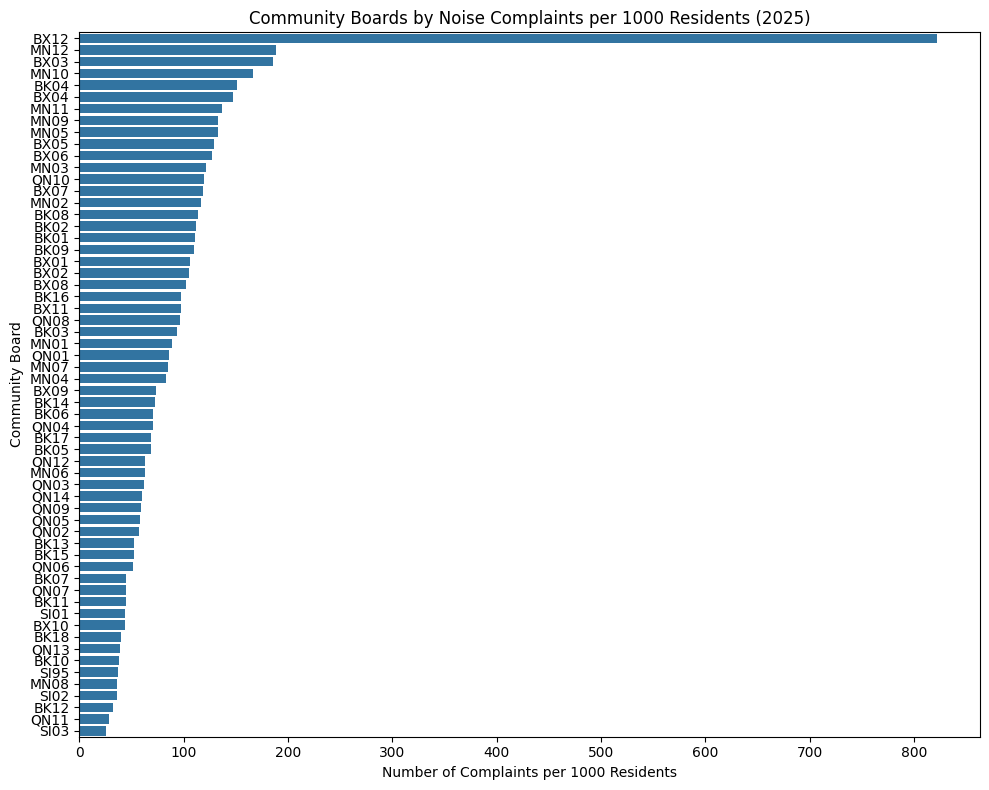

In [180]:
plt.figure(figsize=(10,8))
sns.barplot(data=cb_rate_clean, y="cdta", x="complaints_per_1000")
plt.title("Community Boards by Noise Complaints per 1000 Residents (2025)")
plt.xlabel("Number of Complaints per 1000 Residents")
plt.ylabel("Community Board")
plt.tight_layout()

In [93]:
# Load CDTA geospatial data

cdta_gdf = gpd.read_file("/Users/florencebogitsh/Desktop/Jake/Data/Shapefile/2020 Community District Tabulation Areas (CDTAs)_20241006/2020 Community District Tabulation Areas (CDTAs)_20241006.geojson")

cdta_gdf.head()


,shape_area,cdtatype,cdtaname,shape_leng,boroname,borocode,countyfips,cdta2020,geometry
0,131650692.806,0,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),65597.5255051,Brooklyn,3,047,BK01,"MULTIPOLYGON (((-73.9544 40.73911, -73.95428 4..."
1,75922824.2139,0,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,65236.060084,Brooklyn,3,047,BK02,"MULTIPOLYGON (((-73.96929 40.70709, -73.96913 ..."
2,78196399.5681,0,BK03 Bedford-Stuyvesant (CD 3 Approximation),37550.8572191,Brooklyn,3,047,BK03,"MULTIPOLYGON (((-73.91805 40.68721, -73.918 40..."
3,56653206.5425,0,BK04 Bushwick (CD 4 Equivalent),36981.7267258,Brooklyn,3,047,BK04,"MULTIPOLYGON (((-73.89653 40.6824, -73.89661 4..."
4,165456103.647,0,BK05 East New York-Cypress Hills (CD 5 Approxi...,78800.9211872,Brooklyn,3,047,BK05,"MULTIPOLYGON (((-73.88829 40.64672, -73.88829 ..."


In [182]:
# Merge CDTA geospatial data with cb_rate to prepare for mapping
map_df = cdta_gdf.merge(
    cb_rate_clean,
    left_on="cdta2020",
    right_on="cdta"
)

In [183]:
# Add log-transformed complaints per 1000 for better color scaling on the map

map_df["log_complaints_per_1000"] = np.log10(map_df["complaints_per_1000"] + 1)

Text(0.01, -0.04, 'Color scale shows log10(complaints per 1,000 residents + 1).\nFor example, a value of 1.4 ≈ 22 complaints per 1,000; 2.9 ≈ 820 complaints per 1,000.')

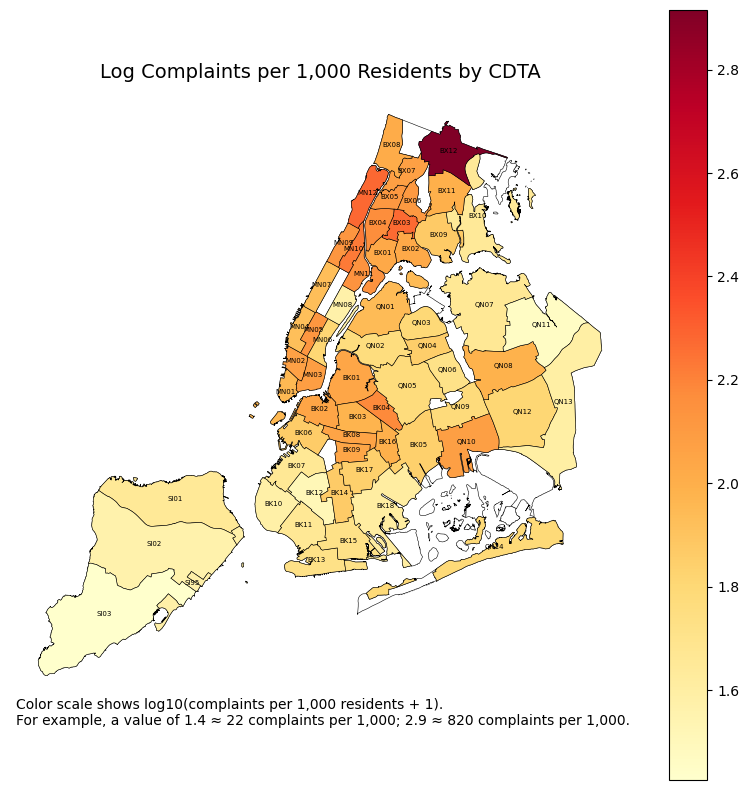

In [185]:
# Plot the map

fig, ax = plt.subplots(figsize=(10,10))

cdta_gdf.plot(
    color="white",
    linewidth=0.4,
    edgecolor="black",
    ax=ax
)

map_df.plot(
    column="log_complaints_per_1000",
    cmap="YlOrRd",
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    ax=ax
)

for idx, row in map_df.iterrows():
    ax.annotate(
        row["cdta"],
        xy=(row.geometry.centroid.x, row.geometry.centroid.y),
        ha='center',
        fontsize=5
    )

ax.set_title("Log Complaints per 1,000 Residents by CDTA", fontsize=14)

ax.axis("off")

# Add explanatory text
ax.text(
    0.01, -0.04,
    "Color scale shows log10(complaints per 1,000 residents + 1).\nFor example, a value of 1.4 ≈ 22 complaints per 1,000; 2.9 ≈ 820 complaints per 1,000.",
    fontsize=10,
    color="black",
    transform=ax.transAxes,
    verticalalignment="bottom",
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
)

(np.float64(-74.28337047814922),
 np.float64(-73.67222994821337),
 np.float64(40.475164048167294),
 np.float64(40.93650271594721))

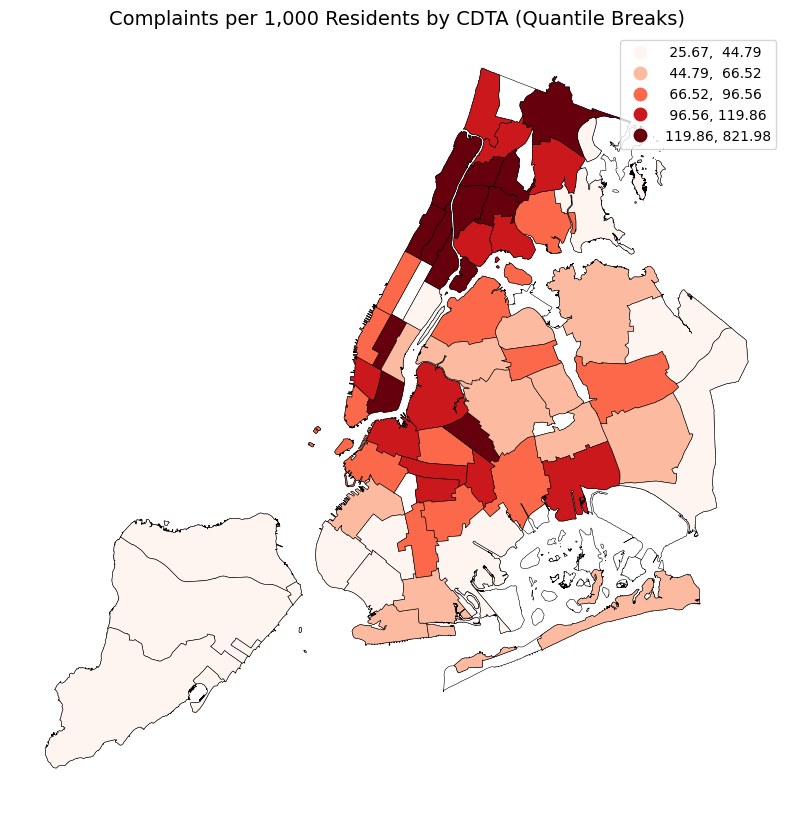

In [186]:
fig, ax = plt.subplots(figsize=(10,10))

cdta_gdf.plot(
    color="white",
    linewidth=0.4,
    edgecolor="black",
    ax=ax
)

map_df.plot(
    column="complaints_per_1000",
    cmap="Reds",
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    scheme="quantiles",  # Discrete breaks
    k=5,                 # Number of bins (adjust as needed)
    ax=ax
)

ax.set_title("Complaints per 1,000 Residents by CDTA (Quantile Breaks)", fontsize=14)
ax.axis("off")

# Question 3 - Response Times

In [187]:
# Calculate response time in hours and days
noise_311_copy["response_hours"] = (noise_311_copy["Closed Date"] - noise_311_copy["Created Date"]).dt.total_seconds() / 3600
noise_311_copy["response_days"] = noise_311_copy["response_hours"] / 24

In [193]:
# Analyze resolution types
res_counts = (
    noise_311_copy["Resolution Description"]
    .value_counts()
)

print(res_counts)

Resolution Description
The Police Department responded to the complaint and with the information available observed no evidence of the violation at that time.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               277402
The Police Department responded to t

In [194]:
def categorize_resolution(desc):

    d = str(desc).lower()

    if "took action" in d or "issued a summons" in d or "made an arrest" in d:
        return "Enforcement Action"

    elif "no evidence" in d or "no criminal violation" in d or "didn't observe a violation" in d:
        return "Investigated – No Violation"

    elif "police action was not necessary" in d:
        return "Investigated – No Action Needed"

    elif "unable to gain entry" in d:
        return "Unable to Access Location"

    elif "those responsible were gone" in d:
        return "Condition Gone on Arrival"

    elif "duplicate" in d:
        return "Duplicate Complaint"

    elif "not under" in d and "jurisdiction" in d:
        return "Outside Jurisdiction"

    elif "insufficient" in d or "contact information" in d:
        return "Insufficient Information"

    elif "responded" in d:
        return "Responded – Other"

    else:
        return "Other"


In [195]:
noise_311_copy["resolution_category"] = noise_311_copy["Resolution Description"].apply(categorize_resolution)

In [196]:
# Calculate average response time by resolution category
satisfactory = [
    "Enforcement Action",
    "Investigated – No Violation",
    "Investigated – No Action Needed"
]

noise_311_copy["satisfactory"] = noise_311_copy["resolution_category"].isin(satisfactory)

In [197]:
# Calculate average response time by satisfactory vs. unsatisfactory resolution
noise_311_copy.groupby("satisfactory")["response_hours"].mean()

satisfactory
False    389.122989
True       7.858738
Name: response_hours, dtype: float64

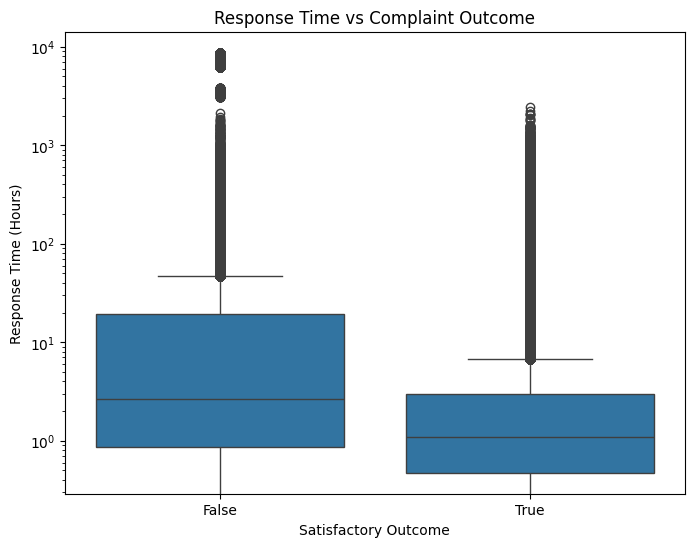

In [206]:
# Visualize response time distribution by satisfactory vs. unsatisfactory resolution

plt.figure(figsize=(8,6))

sns.boxplot(
    data=noise_311_copy,
    x="satisfactory",
    y="response_hours"
)

plt.yscale("log")  # Log scale to handle skewness
plt.xlabel("Satisfactory Outcome")
plt.ylabel("Response Time (Hours)")
plt.title("Response Time vs Complaint Outcome")
plt.show()

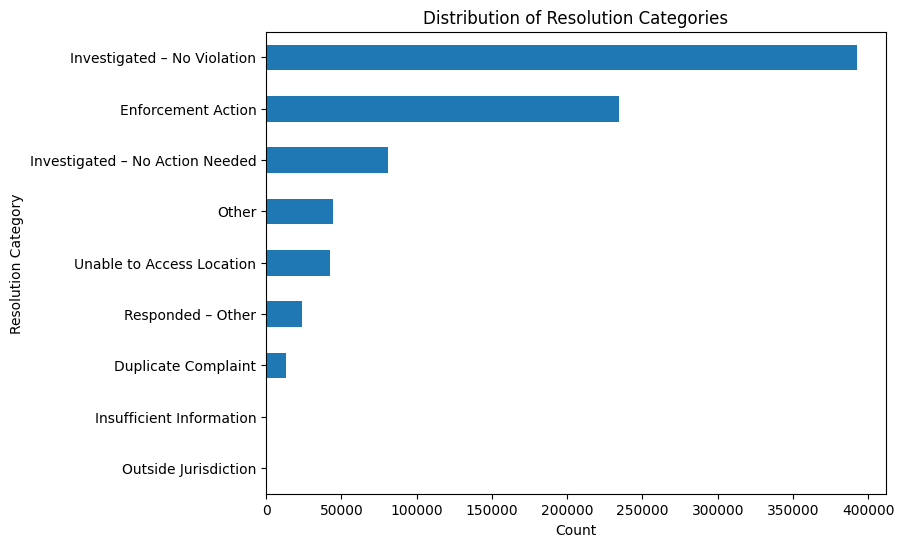

In [208]:
# plot resolution cateogory by value counts

plt.figure(figsize=(8,6))
noise_311_copy["resolution_category"].value_counts().sort_values().plot(kind="barh")
plt.xlabel("Count")
plt.ylabel("Resolution Category")
plt.title("Distribution of Resolution Categories")
plt.show()

In [209]:
# Average and median response times
response_stats = noise_311_copy.groupby("satisfactory")["response_hours"].agg(
    ["mean", "median", "count"]
)

print(response_stats)

                    mean    median   count
satisfactory                              
False         389.122989  2.668056  110869
True            7.858738  1.089444  707957


In [210]:
# Create a binary column for enforcement action
# Does Faster Response Lead to Enforcement?
noise_311_copy["enforcement"] = noise_311_copy["resolution_category"] == "Enforcement Action"

In [211]:
# Create response time bins
noise_311_copy["response_bin"] = pd.cut(
    noise_311_copy["response_hours"],
    bins=[0,1,3,6,12,24,48,96,168],
    labels=[
        "<1 hr",
        "1–3 hrs",
        "3–6 hrs",
        "6–12 hrs",
        "12–24 hrs",
        "1–2 days",
        "2–4 days",
        "4–7 days"
    ]
)

In [212]:
# Calculate enforcement rate by response time bin
enforcement_rate = (
    noise_311_copy
    .groupby("response_bin")["enforcement"]
    .mean()
    .reset_index()
)

/var/folders/sv/tjyf1wqj5hg7zz65thhq45780000gn/T/ipykernel_48997/2776405869.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



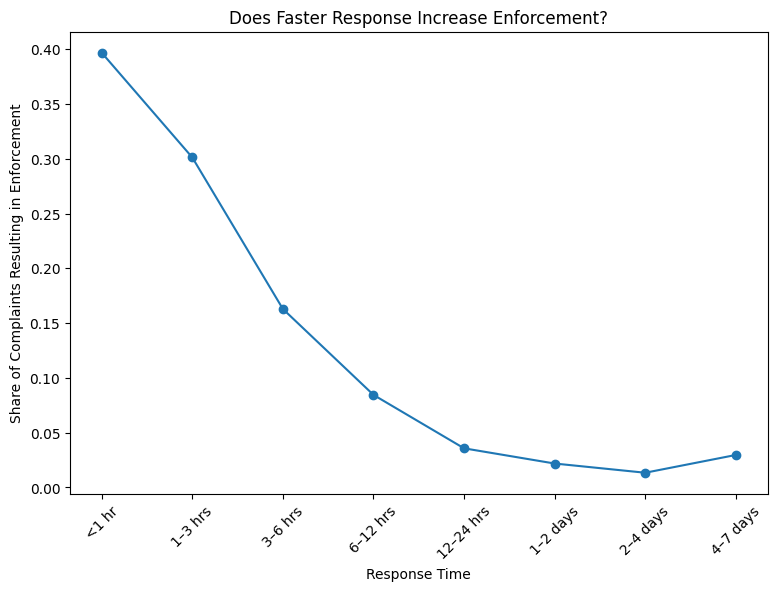

In [213]:
# Visualize enforcement rate by response time bin
plt.figure(figsize=(9,6))

plt.plot(
    enforcement_rate["response_bin"],
    enforcement_rate["enforcement"],
    marker="o"
)

plt.xlabel("Response Time")
plt.ylabel("Share of Complaints Resulting in Enforcement")
plt.title("Does Faster Response Increase Enforcement?")
plt.xticks(rotation=45)

plt.show()

### agency response time timeline

In [216]:
# Create week variable
noise_311_copy["week"] = noise_311_copy["Created Date"].dt.to_period("W").dt.start_time

In [217]:
# Calculate median response time by week and agency
agency_timeline = (
    noise_311_copy
    .groupby(["week", "Agency"])["response_hours"]
    .median()
    .reset_index()
)

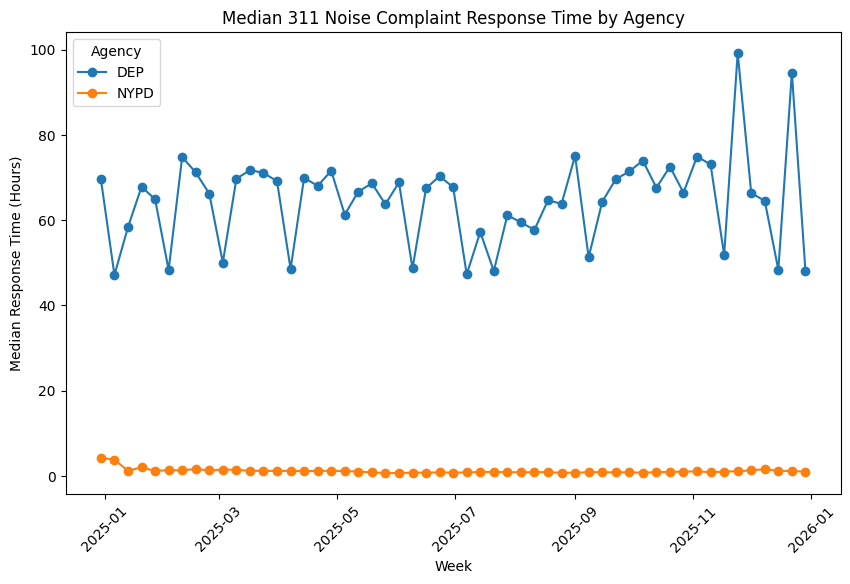

In [229]:
# Visualize response time trends by agency (excluding EDC)
plt.figure(figsize=(10,6))

# Exclude EDC from the agency_timeline
agencies = agency_timeline[agency_timeline["Agency"] != "EDC"]["Agency"].unique()

for agency in agencies:
    subset = agency_timeline[(agency_timeline["Agency"] == agency)]
    plt.plot(
        subset["week"],
        subset["response_hours"],
        marker="o",
        label=agency
    )

plt.xlabel("Week")
plt.ylabel("Median Response Time (Hours)")
plt.title("Median 311 Noise Complaint Response Time by Agency")
plt.legend(title="Agency")
plt.xticks(rotation=45)
plt.show()

In [228]:
# print agency_timeline for DEP and NYPD only to check values

pd.set_option('display.max_rows', None)
print(agency_timeline[agency_timeline["Agency"].isin(["DEP", "NYPD"])])

          week Agency  response_hours
0   2024-12-30    DEP       69.616667
2   2024-12-30   NYPD        4.311667
3   2025-01-06    DEP       47.133333
5   2025-01-06   NYPD        3.805000
6   2025-01-13    DEP       58.341667
8   2025-01-13   NYPD        1.241111
9   2025-01-20    DEP       67.816667
11  2025-01-20   NYPD        2.021806
12  2025-01-27    DEP       64.900000
14  2025-01-27   NYPD        1.189722
15  2025-02-03    DEP       48.316667
17  2025-02-03   NYPD        1.386528
18  2025-02-10    DEP       74.816667
20  2025-02-10   NYPD        1.309722
21  2025-02-17    DEP       71.166667
23  2025-02-17   NYPD        1.653611
24  2025-02-24    DEP       66.216667
26  2025-02-24   NYPD        1.301389
27  2025-03-03    DEP       50.058333
29  2025-03-03   NYPD        1.522500
30  2025-03-10    DEP       69.683333
32  2025-03-10   NYPD        1.440000
33  2025-03-17    DEP       71.716667
35  2025-03-17   NYPD        1.230556
36  2025-03-24    DEP       71.091667
38  2025-03-

### Recommendations to Improve NYC's Response to Noise Complaints

- **Prioritize Rapid Response for High-Impact Complaints:** Focus NYPD and DEP resources on the most disruptive noise types and peak complaint hours, as identified in the analysis, to maximize impact and resident satisfaction.

- **Enhance Inter-Agency Coordination:** Streamline handoffs and clarify roles between NYPD and DEP, ensuring that complaints are routed to the appropriate agency without delay, especially for cases requiring specialized follow-up.

- **Increase Public Awareness and Education:** Launch targeted outreach to inform residents about which agency handles specific noise issues and set realistic expectations for response times, reducing duplicate or misdirected complaints.

- **Leverage Data for Proactive Enforcement:** Use complaint patterns by location and time to guide proactive inspections and enforcement in chronic hotspots, rather than relying solely on reactive responses.

- **Improve Resolution Transparency:** Provide clearer, more detailed updates to complainants about the actions taken and outcomes, which can help build trust and reduce repeat complaints.